<a href="https://colab.research.google.com/github/vazquezsanchezdiegoamaury258/Diplomado/blob/main/clase_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import itertools
from itertools import product

Ejemplo. Lanzamiento de un dado honesto 2 veces
Sea el experimento aleatorio de lanzar un dado honesto 2 veces, entonces sabemos que el espacio muestral es de la siguiente forma:

Ω={(i,j)∣i,j∈{1,2,3,4,5,6}}

y además  |Ω|=62=36 .

In [2]:
Omega = set(product([1,2,3,4,5,6], repeat = 2))
Omega

{(1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (2, 5),
 (2, 6),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4),
 (3, 5),
 (3, 6),
 (4, 1),
 (4, 2),
 (4, 3),
 (4, 4),
 (4, 5),
 (4, 6),
 (5, 1),
 (5, 2),
 (5, 3),
 (5, 4),
 (5, 5),
 (5, 6),
 (6, 1),
 (6, 2),
 (6, 3),
 (6, 4),
 (6, 5),
 (6, 6)}

Definimos el evento

-$S_n$: la suma de los dados es $n$
donde $n\in\{2,3,\dots,12\}$

$$ S_n = \{ (i,j)\in\Omega \mid i+j = n\}$$


In [3]:
#Definimos Sn
def S(n):
  # range genera una secuencia de numeros enteros del 1 al 6
  Sn = {(i,j) for i in range(1,7) for j in range(1,7) if i+j == n}
  return Sn


In [4]:
S_nueve = S(9)
S_nueve

{(3, 6), (4, 5), (5, 4), (6, 3)}

In [5]:
S_cinco = S(5)
S_cinco

{(1, 4), (2, 3), (3, 2), (4, 1)}

In [6]:
1 #vamos a trabajar con fracciones
from fractions import Fraction


In [7]:
def P(A):
  P = Fraction(len(A), len(Omega))
  return P

Vamos a agrupar combinaciones por suma y para esto vamos a usar defaultic(set) para crear un diccionario cuyas clabes tengan como valor un conjunto vacio por defecto.


In [9]:
Sn = { (i,j) : i+j for i,j in Omega }

In [10]:
from collections import defaultdict

# Recorrer y agrupar por  suma
dSn = defaultdict(set)

In [11]:
for i,j in Sn.items():
  dSn[j].add(i)

In [12]:
list(dSn.items())

[(7, {(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)}),
 (4, {(1, 3), (2, 2), (3, 1)}),
 (9, {(3, 6), (4, 5), (5, 4), (6, 3)}),
 (10, {(4, 6), (5, 5), (6, 4)}),
 (6, {(1, 5), (2, 4), (3, 3), (4, 2), (5, 1)}),
 (8, {(2, 6), (3, 5), (4, 4), (5, 3), (6, 2)}),
 (11, {(5, 6), (6, 5)}),
 (3, {(1, 2), (2, 1)}),
 (5, {(1, 4), (2, 3), (3, 2), (4, 1)}),
 (2, {(1, 1)}),
 (12, {(6, 6)})]

In [13]:
#Vamos a crear la ley de densidad de Sn
LeySn = {i : P(A) for i,A in dSn.items()}
LeySn

{7: Fraction(1, 6),
 4: Fraction(1, 12),
 9: Fraction(1, 9),
 10: Fraction(1, 12),
 6: Fraction(5, 36),
 8: Fraction(5, 36),
 11: Fraction(1, 18),
 3: Fraction(1, 18),
 5: Fraction(1, 9),
 2: Fraction(1, 36),
 12: Fraction(1, 36)}

In [14]:
import pandas as pd


In [19]:
Ley_Sn = pd.Series(LeySn)
Ley_Sn

,0
7,1/6
4,1/12
9,1/9
10,1/12
6,5/36
8,5/36
11,1/18
3,1/18
5,1/9
2,1/36


In [20]:
Ley_Sn = Ley_Sn.sort_index()
Ley_Sn

,0
2,1/36
3,1/18
4,1/12
5,1/9
6,5/36
7,1/6
8,5/36
9,1/9
10,1/12
11,1/18


In [21]:
# Vamos a definir la función de densidad (ley de Sn)
import numpy as np

def LeyS(i):
    if i in range(2,13): # es de 2 hasta 12
        x = LeySn[i] # me asigne probabilidad
    else:
        x = 0 # no me asigne probabilidad
    return x

In [22]:
# Creamos el rango de la v.a.
rango_S = [k for k in range(2,13)]

# Obtenemos la probabilidad de cada suma en el rango de S
p_k = [float(LeyS(k)) for k in rango_S]
p_k

[0.027777777777777776,
 0.05555555555555555,
 0.08333333333333333,
 0.1111111111111111,
 0.1388888888888889,
 0.16666666666666666,
 0.1388888888888889,
 0.1111111111111111,
 0.08333333333333333,
 0.05555555555555555,
 0.027777777777777776]

In [23]:
sum(p_k)


1.0

In [25]:
lS = pd.DataFrame(list(zip(rango_S, p_k)),
                  index = [f'S_{k}' for k in rango_S],
                  columns = ['rango','densidad'])
lS

,rango,densidad
S_2,2,0.027778
S_3,3,0.055556
S_4,4,0.083333
S_5,5,0.111111
S_6,6,0.138889
S_7,7,0.166667
S_8,8,0.138889
S_9,9,0.111111
S_10,10,0.083333
S_11,11,0.055556


<Axes: xlabel='rango'>

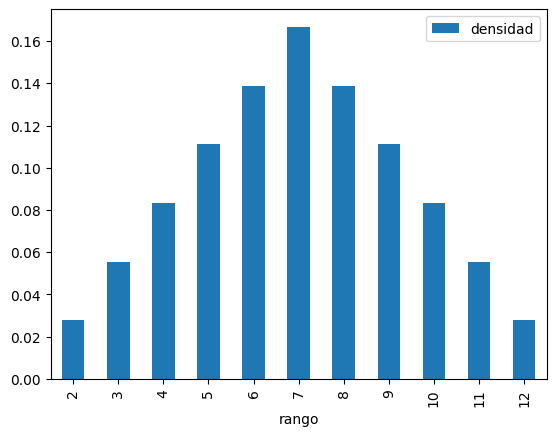

In [27]:
lS.plot.bar( x = 'rango', y = 'densidad')